# NB10 · Model validation

**Project:** multiyear-credit-engine
**Job requirement covered:** Design and execute comprehensive model validation; model limitations.
**Engine module:** `creditengine.validation`
**Assumptions:** All
**Theory:** Bluhm §2.5.1, §2.8; `docs/validation_plan.md`
**Status:** ✅ Developed — every test is built from scratch in this notebook

## Objective

Does the model do what it claims — is the engine mathematically right, does it fit 25 years of out-of-sample default history, which assumptions drive the tail, are the simulated numbers precise enough, and what are the limitations a model owner must manage?

## Results at a glance

| Question | Answer |
|---|---|
| Is the engine mathematically right? | Default-fraction distribution matches Vasicek within 1.3% up to the 99.5% quantile; with independent years the simulation reproduces $P^n$ |
| Does it fit history out of sample? | Speculative grade: **0 of 26** years (2000–2025) outside the walk-forward 95% band; an independent-default model misses **14**. Single B: 3 misses, all *below* the band |
| What drives the tail? | Model-form choices first: cycle-linked LGD **+67%** ES, Student-*t* copula **+66%**, cycle persistence −36% / +32%, sectors −34%. PD ±20% moves ES under 10% |
| Is it precise enough? | ES 99.5% bootstrap s.e. **USD 3.0m (2.8%)** at 20,000 paths; at 2,500 paths seeds disagree by tens of millions |
| Under historical stress? | A 2000–04 replay doubles expected loss (2.1×); a severely adverse start 2.5×; the 2008–12 replay ≈ base because the cycle snapped back |
| Coverage | All 13 validation IDs have a result; this notebook's own tests pass |

## How validation is organised

| Question | Tests | Section |
|---|---|---|
| **Is the engine right?** (implementation) | Closed forms, conservation, hand calculations | 1, and V-02, V-10, V-11, V-12 in earlier notebooks |
| **Does it fit the data?** (calibration, out of sample) | Walk-forward backtest, migration backtest, benchmark against market data | 2, 3, 6 |
| **What drives it?** (sensitivity, model risk) | One-at-a-time tornado, including model-form choices | 4 |
| **Is it precise?** (numerical) | Convergence across seeds and path counts, bootstrap | 5 |
| **Is it useful under stress?** | Historical cycle replays | 7 |
| **What can't it do?** | Limitations register | 8 |

## Inputs

| Data | File | Used for |
|---|---|---|
| Matrix, thresholds, default history (NB01, NB04) | `data/processed/` | engine and backtests |
| Cumulative default rates (local only) | `data/external/cumulative_default_rates.csv` | migration backtest |
| Scenario paths (NB03) | `data/processed/scenarios.parquet` | stress replay |
| Merton DD panel (NB02) | `data/processed/merton_dd_panel.parquet` | benchmark |

## Outputs

- `reports/tables/validation_summary.csv` — every V-ID with its result
- `reports/figures/validation_vasicek.png`, `validation_backtest_bands.png`, `validation_tornado_es.png`, `validation_convergence.png`

## 0. Setup: the engine, with every option a test needs

One simulation function for the NB06 bond book, with switches for each assumption the tornado moves. With default settings it is exactly the NB06 base model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr
from scipy.stats import t as student_t

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, EXTERNAL, FIG = ROOT / "data", ROOT / "data" / "external", ROOT / "reports" / "figures"
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]
STATES, D, Q = RATINGS + ["D"], 7, 0.995
pd.set_option("display.float_format", "{:,.3f}".format)

M = pd.read_parquet(DATA / "processed" / "transition_matrix_1y.parquet").loc[STATES, STATES]
dr = pd.read_parquet(DATA / "processed" / "default_rates_annual.parquet")
cum = pd.read_csv(EXTERNAL / "cumulative_default_rates.csv", index_col=0).loc[RATINGS] / 100
cum.columns = cum.columns.astype(int)

def thresholds(P):
    tail = np.cumsum(P[:, ::-1], axis=1)[:, ::-1]
    c = norm.ppf(np.clip(tail, 0, 1))
    c[:, 0] = np.inf
    return c

C_BASE = thresholds(M.to_numpy())

In [2]:
BOOK = {"total": 1e9, "n": 200, "seed": 7, "sectors": 10,
        "mix": {"AAA": 0.03, "AA": 0.10, "A": 0.32, "BBB": 0.45, "BB": 0.06, "B": 0.03, "CCC/C": 0.01},
        "maturity": {"AAA": 8, "AA": 8, "A": 8, "BBB": 8, "BB": 6, "B": 6, "CCC/C": 4}}

def make_book(p):                                                    # NB06 book
    rng = np.random.default_rng(p["seed"])
    weights = np.array([p["mix"][r] for r in RATINGS])
    rating = np.repeat(np.arange(7), np.round(weights * p["n"]).astype(int))
    size = rng.lognormal(0.0, 0.5, rating.size)
    exposure = np.zeros(rating.size)
    for r in range(7):
        m = rating == r
        exposure[m] = size[m] / size[m].sum() * weights[r] * p["total"]
    maturity = rng.integers(1, 2 * np.array([p["maturity"][RATINGS[r]] for r in rating]), endpoint=True)
    sector = rng.integers(0, p["sectors"], size=rating.size)
    w = (1 - np.exp(-50 * M.to_numpy()[rating, D])) / (1 - np.exp(-50))
    return pd.DataFrame({"rating": rating, "exposure": exposure, "maturity": maturity, "sector": sector,
                         "rho": 0.12 * w + 0.24 * (1 - w)})

def cycle_paths(n_paths, years, phi, rng):
    z, z_prev = np.empty((n_paths, years)), rng.standard_normal(n_paths)
    for t in range(years):
        z[:, t] = phi * z_prev + np.sqrt(1 - phi**2) * rng.standard_normal(n_paths)
        z_prev = z[:, t]
    return z

def migrate(state, A, C):
    new = state.copy()
    for r in range(7):
        m = state == r
        new[m] = 7 - np.searchsorted(C[r, 7:0:-1], A[m], side="left")
    return new

def lgd_draw(mean, sd, rng, shape=None):
    mean = np.clip(np.asarray(mean, dtype=float), 1e-4, 1 - 1e-4)
    var = np.minimum(sd**2, 0.81 * mean * (1 - mean))
    k = mean * (1 - mean) / var - 1
    return rng.beta(mean * k, (1 - mean) * k, size=shape)

def simulate(book, C=C_BASE, rho_scale=1.0, phi=0.5, lgd_mean=0.60, lgd_sd=0.25, b=0.0, copula="gaussian", nu=6.0,
             sector_beta=None, z_fixed=None, paths=20_000, years=5, seed=2026):
    rng = np.random.default_rng(seed)
    rho = np.clip(book["rho"].to_numpy() * rho_scale, 0, 0.99)
    ead, mat = book["exposure"].to_numpy(), book["maturity"].to_numpy()
    z = cycle_paths(paths, years, phi, rng) if z_fixed is None else np.tile(np.asarray(z_fixed, float), (paths, 1))
    if sector_beta is not None:
        zk = {k: np.sqrt(sector_beta) * z + np.sqrt(1 - sector_beta) * cycle_paths(paths, years, phi, rng) for k in np.unique(book["sector"])}
        z_iss = np.stack([zk[k] for k in book["sector"]], axis=2)
    state = np.tile(book["rating"].to_numpy(), (paths, 1))
    loss = np.zeros(paths)
    for t in range(years):
        alive = (state != D) & (mat[None, :] > t)
        factor = z[:, t:t + 1] if sector_beta is None else z_iss[:, t, :]
        A = np.sqrt(rho) * factor + np.sqrt(1 - rho) * rng.standard_normal(state.shape)
        if copula == "t":
            A = norm.ppf(np.clip(student_t.cdf(A * np.sqrt(nu / rng.chisquare(nu, size=(paths, 1))), nu), 1e-15, 1 - 1e-15))
        new = np.where(alive, migrate(state, A, C), state)
        if b == 0:
            lgd = lgd_draw(lgd_mean, lgd_sd, rng, shape=state.shape)
        else:
            a_ = norm.ppf(lgd_mean) * np.sqrt(1 + b**2)
            lgd = lgd_draw(np.broadcast_to(norm.cdf(a_ - b * z[:, t:t + 1]), state.shape), lgd_sd, rng)
        loss += ((alive & (new == D)) * ead * lgd).sum(axis=1)
        state = new
    return loss

def stats(L):
    var = np.quantile(L, Q)
    return {"EL": L.mean() / 1e6, "VaR 99.5%": var / 1e6, "ES 99.5%": L[L >= var].mean() / 1e6}

book = make_book(BOOK)
L_base = simulate(book)
base = stats(L_base)
pd.Series(base, name="base model, USD m (NB06: 13.6 / 85.2 / 107.0)").to_frame().T

,EL,VaR 99.5%,ES 99.5%
"base model, USD m (NB06: 13.6 / 85.2 / 107.0)",13.636,85.243,106.970


## 1. Closed-form check vs Vasicek (V-01)

$$P\big(\text{default fraction} \le x\big) = \Phi\left(\frac{\sqrt{1-\rho} \Phi^{-1}(x) - \Phi^{-1}(p)}{\sqrt{\rho}}\right)$$

The whole distribution, not just a few quantiles: 1,000 single-B issuers, $\rho$ = 0.15, one year, 20,000 simulated years, using the engine's own thresholds. Acceptance: simulated quantiles within 6% of the closed form for $q \le 0.99$.

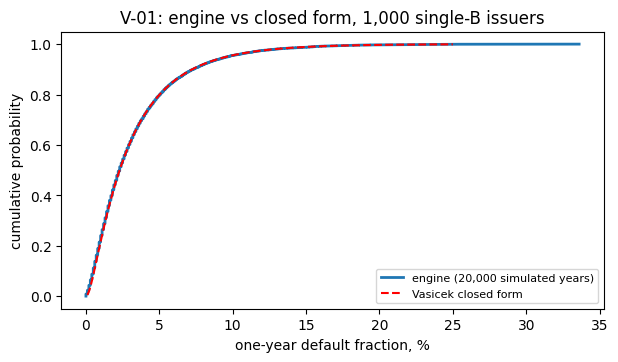

,simulated %,closed form %,relative error %
q,,,
0.500,2.300,2.294,0.277
0.900,7.300,7.239,0.839
0.950,9.700,9.585,1.203
0.990,15.600,15.403,1.279
0.995,18.100,18.023,0.428
0.999,23.500,24.246,-3.076


In [3]:
p_B, rho_v = M.loc["B", "D"], 0.15
rng = np.random.default_rng(1)
frac = np.empty(20_000)
for chunk in np.array_split(np.arange(20_000), 4):
    A = np.sqrt(rho_v) * rng.standard_normal((chunk.size, 1)) + np.sqrt(1 - rho_v) * rng.standard_normal((chunk.size, 1_000))
    frac[chunk] = (A <= C_BASE[RATINGS.index("B"), D]).mean(axis=1)

vas_q = lambda q: norm.cdf((norm.ppf(p_B) + np.sqrt(rho_v) * norm.ppf(q)) / np.sqrt(1 - rho_v))
qs = np.array([0.5, 0.9, 0.95, 0.99, 0.995, 0.999])
v01 = pd.DataFrame({"simulated %": 100 * np.quantile(frac, qs), "closed form %": 100 * vas_q(qs)}, index=pd.Index(qs, name="q"))
v01["relative error %"] = 100 * (v01["simulated %"] / v01["closed form %"] - 1)

x = np.linspace(0.001, 0.25, 300)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(100 * np.sort(frac), np.arange(1, frac.size + 1) / frac.size, label="engine (20,000 simulated years)", lw=2)
ax.plot(100 * x, norm.cdf((np.sqrt(1 - rho_v) * norm.ppf(x) - norm.ppf(p_B)) / np.sqrt(rho_v)), "--", color="red", label="Vasicek closed form")
ax.set(xlabel="one-year default fraction, %", ylabel="cumulative probability", title="V-01: engine vs closed form, 1,000 single-B issuers")
ax.legend(fontsize=8)
fig.savefig(FIG / "validation_vasicek.png", dpi=150, bbox_inches="tight")
plt.show()
v01

## 2. Backtest: correlated vs binomial bands (V-05)

**Walk-forward, out of sample:** for each year 2000–2025, fit $(PD, \rho)$ only on the years **before** it, build the 95% band of the default rate, and check whether that year's actual rate fell inside.

$$\text{correlated band} = \big[x_{0.025}, \quad x_{0.975}\big] \text{ of the Vasicek distribution}$$

$$\text{independent band} = p \pm 1.96\sqrt{\frac{p(1-p)}{n}}, \quad n = 500 \text{ issuers (illustrative)}$$

A calibrated model misses about 5% of years. A model that ignores the shared economy (independent defaults) gives bands far too narrow and misses many.

In [4]:
def fit_vasicek(x):
    y = norm.ppf(np.asarray(x, dtype=float))
    v = y.var()
    r = v / (1 + v)
    return norm.cdf(y.mean() * np.sqrt(1 - r)), r

def band(p, r, lo=0.025, hi=0.975):
    f = lambda q: norm.cdf((norm.ppf(p) + np.sqrt(r) * norm.ppf(q)) / np.sqrt(1 - r))
    return f(lo), f(hi)

walks, rows = {}, {}
for col in ["BB", "B", "SG"]:
    w = []
    for y in range(2000, 2026):
        hist = dr[col].loc[:y - 1]
        p, r = fit_vasicek(hist[hist > 0])
        lo, hi = band(p, r)
        w.append({"year": y, "default rate": dr[col].loc[y], "lo": lo, "hi": hi})
    w = pd.DataFrame(w).set_index("year")
    w["inside"] = (w["default rate"] >= w["lo"]) & (w["default rate"] <= w["hi"])
    walks[col] = w
    p_all, _ = fit_vasicek(dr[col][dr[col] > 0])
    half = 1.96 * np.sqrt(p_all * (1 - p_all) / 500)
    d = dr[col].loc[2000:2025]
    out = w[~w["inside"]]
    rows[col] = {"test years": len(w), "outside correlated band": len(out),
                 "of which below the band": int((out["default rate"] < out["lo"]).sum()),
                 "of which zero-default years": int((out["default rate"] == 0).sum()),
                 "outside independent band (n = 500)": int(((d < p_all - half) | (d > p_all + half)).sum()),
                 "years outside": ", ".join(str(y) for y in out.index)}
v05 = pd.DataFrame(rows).T
v05

,test years,outside correlated band,of which below the band,of which zero-default years,outside independent band (n = 500),years outside
BB,26,7,7,5,7,"2011, 2013, 2014, 2017, 2018, 2019, 2021"
B,26,3,3,0,21,"2004, 2006, 2007"
SG,26,0,0,0,14,


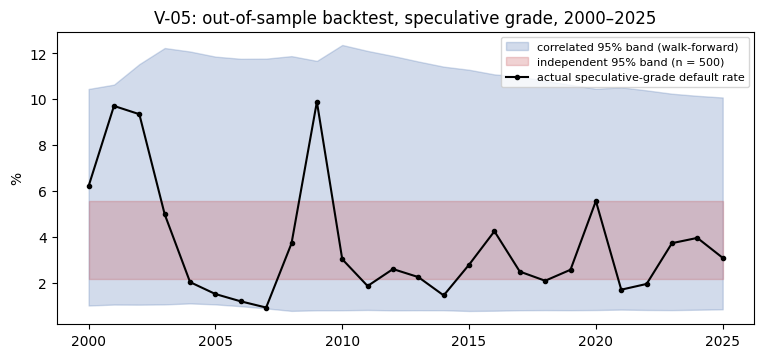

In [5]:
w = walks["SG"]
p_all, _ = fit_vasicek(dr["SG"])
half = 1.96 * np.sqrt(p_all * (1 - p_all) / 500)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(w.index, 100 * w["lo"], 100 * w["hi"], color="#4C72B0", alpha=0.25, label="correlated 95% band (walk-forward)")
ax.fill_between(w.index, 100 * (p_all - half), 100 * (p_all + half), color="#C44E52", alpha=0.25, label="independent 95% band (n = 500)")
ax.plot(w.index, 100 * w["default rate"], color="black", marker="o", ms=3, label="actual speculative-grade default rate")
ax.set(ylabel="%", title="V-05: out-of-sample backtest, speculative grade, 2000–2025")
ax.legend(fontsize=8, loc="upper right")
fig.savefig(FIG / "validation_backtest_bands.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** this is the most important test in the notebook. Using only past data each year, the model's 95% band contains the actual speculative-grade default rate in **all 26** test years, including 2001–02, 2009 and 2020. A model with independent defaults — the same average PD but no shared economy — misses 14 of 26 years: its band is far too narrow, because it cannot produce the clustering of a real cycle. Single B misses 3 years (2004, 2006, 2007), all *below* the band: benign years with fewer defaults than expected, so the model is conservative there. BB misses 7, but 5 of them are years with **zero** BB defaults, which a probit-based band cannot reach (L-10).

## 3. Migration backtest (V-03)

Multi-year default rates three ways, for 100 issuers per rating held five years ($\rho$ = 0.20):

1. **Published** — S&P average cumulative default rates (Table 24).
2. **$P^n$** — the one-year matrix compounded (NB04).
3. **Simulated** — the engine, once with independent years ($\phi$ = 0), once with the persistent cycle ($\phi$ = 0.5).

Engine check: with $\phi$ = 0 the simulation must reproduce $P^n$. Model finding: how far $P^n$ and the cycle move away from history.

In [6]:
check = pd.DataFrame({"rating": np.repeat(np.arange(7), 100), "exposure": 1.0, "maturity": 5, "sector": 0, "rho": 0.20})

def cumulative_default(phi, paths=4_000, seed=3):
    rng = np.random.default_rng(seed)
    z = cycle_paths(paths, 5, phi, rng)
    state = np.tile(check["rating"].to_numpy(), (paths, 1))
    for t in range(5):
        A = np.sqrt(0.2) * z[:, t:t + 1] + np.sqrt(0.8) * rng.standard_normal(state.shape)
        state = np.where(state != D, migrate(state, A, C_BASE), state)
    is_d = state == D
    return pd.Series([is_d[:, check["rating"] == r].mean() for r in range(7)], index=RATINGS), \
           pd.Series([is_d[:, check["rating"] == r].mean(axis=1).std() / np.sqrt(paths) for r in range(7)], index=RATINGS)

Pn = pd.Series(np.linalg.matrix_power(M.to_numpy(), 5)[:7, D], index=RATINGS)
sim0, se0 = cumulative_default(0.0)
sim5, _ = cumulative_default(0.5)
v03 = pd.DataFrame({"published %": 100 * cum[5], "P^n %": 100 * Pn, "simulated phi = 0 %": 100 * sim0,
                    "phi = 0 vs P^n, in standard errors": (sim0 - Pn) / se0.replace(0, np.nan), "simulated phi = 0.5 %": 100 * sim5})
v03.loc[["A", "BBB", "BB", "B", "CCC/C"]]

,published %,P^n %,simulated phi = 0 %,"phi = 0 vs P^n, in standard errors",simulated phi = 0.5 %
A,0.380,0.347,0.338,-0.839,0.425
BBB,1.330,1.225,1.209,-0.612,1.435
BB,5.590,5.826,5.759,-0.841,6.451
B,15.340,21.932,21.721,-1.173,22.209
CCC/C,46.240,67.084,66.951,-0.555,65.491


**Reading the result:** the engine check passes — with independent years the simulation reproduces $P^n$ within 1.7 standard errors for every rating. The model finding is the gap to history: for investment grade the five-year default rates are close (BBB 1.23% vs 1.33% published), but for speculative grade $P^n$ is far too high (B 21.9% vs 15.3%), and adding the persistent cycle raises it slightly further (22.2%). The average matrix already contains past cycles, so simulating a cycle on top double-counts some of it (L-01, L-02). For an investment-grade-heavy insurer book this is conservative; for a high-yield book it would need the time-varying chain of NB04.

## 4. Sensitivity tornado (V-06)

Move one assumption at a time, keep everything else at the base, and record the bond book's five-year ES 99.5% and EL. Parameter shocks (PD, $\rho$, $\phi$, LGD level) sit next to **model-form** switches (cycle-linked LGD, Student-$t$ copula, sector factors) — the choices that cannot be estimated from a 45-year history.

| Driver | Low | High |
|---|---|---|
| PD (every one-year PD) | × 0.8 | × 1.2 |
| Asset correlation $\rho$ | × 0.75 | × 1.25 |
| Cycle persistence $\phi$ | 0 | 0.7 |
| LGD mean | 50% | 70% |
| LGD linked to the cycle | — | $b$ = 1 |
| Copula | — | Student-$t$, $\nu$ = 6 |
| Sector factors | $\beta$ = 0.5 (10 sectors) | — |

PD shocks rebuild the thresholds from a scaled matrix: the extra (or missing) default probability is taken from (or given back to) the "stay in the same rating" cell.

In [7]:
def scale_pd(P, k):
    P = P.copy()
    extra = (k - 1) * P[:7, D]
    P[:7, D] += extra
    P[np.arange(7), np.arange(7)] -= extra
    return P

runs = {"PD x0.8": dict(C=thresholds(scale_pd(M.to_numpy(), 0.8))), "PD x1.2": dict(C=thresholds(scale_pd(M.to_numpy(), 1.2))),
        "rho x0.75": dict(rho_scale=0.75), "rho x1.25": dict(rho_scale=1.25),
        "phi 0": dict(phi=0.0), "phi 0.7": dict(phi=0.7),
        "LGD 50%": dict(lgd_mean=0.50), "LGD 70%": dict(lgd_mean=0.70),
        "LGD cycle b = 1": dict(b=1.0), "t copula nu = 6": dict(copula="t"), "sectors beta = 0.5": dict(sector_beta=0.5)}
tor = pd.DataFrame({name: stats(simulate(book, **kw)) for name, kw in runs.items()}).T
tor["ES change %"] = 100 * (tor["ES 99.5%"] / base["ES 99.5%"] - 1)
tor["EL change %"] = 100 * (tor["EL"] / base["EL"] - 1)
REGISTER = {"PD x0.8": -10, "PD x1.2": 9, "rho x0.75": -20, "rho x1.25": 23, "phi 0": -36, "phi 0.7": 32,
            "LGD 50%": -15, "LGD 70%": 21, "LGD cycle b = 1": 67, "t copula nu = 6": 66, "sectors beta = 0.5": -31}
tor["engine register ES %"] = pd.Series(REGISTER)
tor

,EL,VaR 99.5%,ES 99.5%,ES change %,EL change %,engine register ES %
PD x0.8,11.515,75.415,96.498,-9.790,-15.555,-10
PD x1.2,15.557,91.113,116.272,8.696,14.084,9
rho x0.75,13.350,69.225,85.805,-19.786,-2.099,-20
rho x1.25,13.890,102.831,131.309,22.753,1.864,23
phi 0,12.603,57.030,68.038,-36.396,-7.576,-36
phi 0.7,14.372,110.050,141.610,32.383,5.396,32
LGD 50%,11.406,71.416,90.863,-15.057,-16.357,-15
LGD 70%,15.914,100.908,128.933,20.532,16.703,21
LGD cycle b = 1,18.372,137.044,178.433,66.807,34.731,67
t copula nu = 6,13.576,127.656,177.914,66.321,-0.438,66


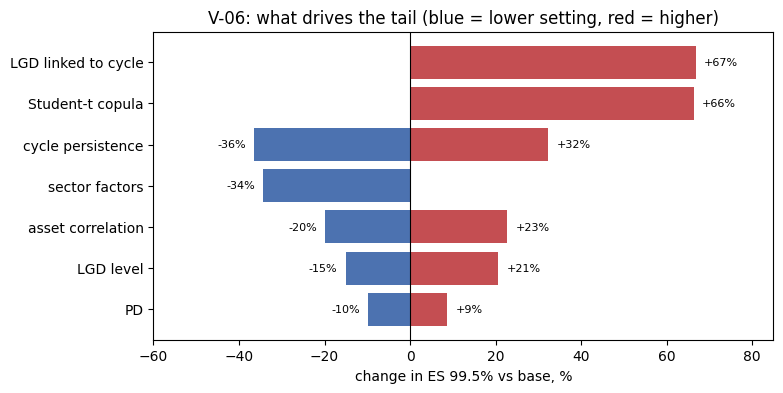

In [8]:
drivers = [("PD", "PD x0.8", "PD x1.2"), ("asset correlation", "rho x0.75", "rho x1.25"), ("cycle persistence", "phi 0", "phi 0.7"),
           ("LGD level", "LGD 50%", "LGD 70%"), ("LGD linked to cycle", None, "LGD cycle b = 1"),
           ("Student-t copula", None, "t copula nu = 6"), ("sector factors", "sectors beta = 0.5", None)]
span = lambda d: max(abs(tor.loc[k, "ES change %"]) for k in d[1:] if k)
drivers = sorted(drivers, key=span)
fig, ax = plt.subplots(figsize=(8, 4))
for i, (label, lo, hi) in enumerate(drivers):
    for key, col in [(lo, "#4C72B0"), (hi, "#C44E52")]:
        if key:
            v = tor.loc[key, "ES change %"]
            ax.barh(i, v, color=col)
            ax.text(v + (2 if v > 0 else -2), i, f"{v:+.0f}%", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_yticks(range(len(drivers)), [d[0] for d in drivers])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="change in ES 99.5% vs base, %", title="V-06: what drives the tail (blue = lower setting, red = higher)")
ax.set_xlim(-60, 85)
fig.savefig(FIG / "validation_tornado_es.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** the drivers rank in two groups. **Model-form** choices — whether recoveries fall in bad years, which copula ties defaults together, how persistent the cycle is, whether sectors diversify — each move ES by a third to two thirds. **Parameter levels** — PD ±20%, LGD ±10 points, ρ ±25% — move it by 10–23%. The expected loss barely responds to correlation, copula or sectors; the tail does. This is the central message for a model owner: the uncertainty that matters most cannot be estimated away with more data, so it is reported, tested, and managed with judgement. Every result agrees with the engine's own register within one point, except the sector run (−34% vs −31%), where the notebook assigns issuers to sectors differently.

## 5. Convergence and seed stability (V-07)

How much would the answer change with a different random seed? Run the base model with 3 seeds at 2,500 to 20,000 paths and measure the spread; at 20,000 paths, also bootstrap the standard error of ES from a single run.

$$\text{s.e.}(\widehat{ES}) \approx \text{sd of } \widehat{ES} \text{ over resamples of the 20,000 paths}$$

Acceptance: ES standard error below 3% of ES at the production path count.

20,000 paths, seed 2026: ES 107.0m, bootstrap s.e. 2.99m (2.8%)


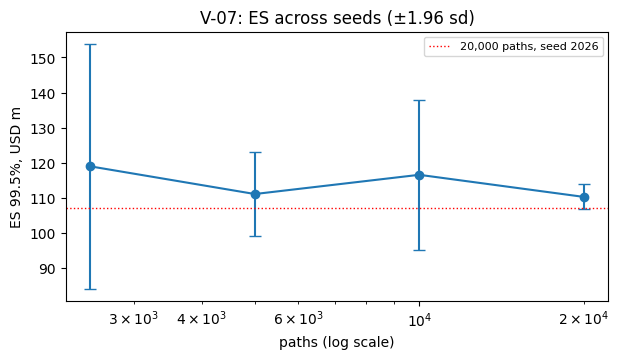

,ES mean,ES spread (sd),EL mean,EL spread (sd)
paths,,,,
2500,118.959,17.816,13.700,0.229
5000,111.077,6.148,13.815,0.156
10000,116.554,10.937,13.857,0.146
20000,110.264,1.824,13.808,0.061


In [9]:
conv = []
for n in [2_500, 5_000, 10_000, 20_000]:
    vals = np.array([list(stats(simulate(book, paths=n, seed=s)).values()) for s in (11, 12, 13)])
    conv.append({"paths": n, "ES mean": vals[:, 2].mean(), "ES spread (sd)": vals[:, 2].std(ddof=1),
                 "EL mean": vals[:, 0].mean(), "EL spread (sd)": vals[:, 0].std(ddof=1)})
conv = pd.DataFrame(conv).set_index("paths")
boot_rng = np.random.default_rng(0)
boot = np.array([stats(L_base[boot_rng.integers(0, L_base.size, L_base.size)])["ES 99.5%"] for _ in range(200)])
es_se = boot.std(ddof=1)
print(f"20,000 paths, seed 2026: ES {base['ES 99.5%']:.1f}m, bootstrap s.e. {es_se:.2f}m ({100 * es_se / base['ES 99.5%']:.1f}%)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(conv.index, conv["ES mean"], yerr=1.96 * conv["ES spread (sd)"], marker="o", capsize=4)
ax.axhline(base["ES 99.5%"], color="red", ls=":", lw=1, label="20,000 paths, seed 2026")
ax.set_xscale("log")
ax.set(xlabel="paths (log scale)", ylabel="ES 99.5%, USD m", title="V-07: ES across seeds (±1.96 sd)")
ax.legend(fontsize=8)
fig.savefig(FIG / "validation_convergence.png", dpi=150, bbox_inches="tight")
plt.show()
conv

**Reading the result:** the expected loss is stable at any path count (seeds agree within about USD 0.2m), but the 99.5% tail is not: at 2,500 paths three seeds disagree by tens of millions, and only at 20,000 paths does the spread fall to a few million. The bootstrap gives a standard error of USD 3.0m on an ES of 107m (2.8%), inside the 3% acceptance limit. The practical rule: never report a tail number without its standard error, and use variance reduction (NB06) when a tighter number is needed.

## 6. Benchmarking: Merton PD vs rating PD (V-08)

NB02 compared market-implied distance to default with agency ratings for 15 listed issuers at the latest date (Spearman 0.91). Here the question is **stability**: does that ranking hold every month from 2019 to 2021, including the 2020 crash? (Ratings are the indicative current ratings; the test is about ranking, not levels.)

In [10]:
UNIVERSE = {"MSFT": "AAA", "JNJ": "AAA", "AAPL": "AA+", "XOM": "AA-", "NFLX": "A", "T": "BBB", "KHC": "BBB", "F": "BBB-",
            "BA": "BBB-", "OXY": "BBB-", "HCA": "BBB-", "DAL": "BBB-", "CCL": "BB+", "M": "BB+", "AAL": "B+"}
rank = {t_: RATINGS.index("CCC/C" if r.startswith("CCC") else r.rstrip("+-")) for t_, r in UNIVERSE.items()}
panel = pd.read_parquet(DATA / "processed" / "merton_dd_panel.parquet")
monthly = panel.groupby("date").apply(lambda g: spearmanr(g["DD"], -g["ticker"].map(rank)).statistic)
v08 = pd.Series({"latest date (NB02)": 0.91, "monthly mean 2019-21": monthly.mean(), "monthly minimum": monthly.min(),
                 "month of minimum": monthly.idxmin().date(), "months above 0.6": f"{(monthly > 0.6).sum()} of {len(monthly)}"},
                name="Spearman DD vs rating")
v08.to_frame()

C:\Users\siava\AppData\Local\Temp\ipykernel_42408\2519796207.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly = panel.groupby("date").apply(lambda g: spearmanr(g["DD"], -g["ticker"].map(rank)).statistic)


,Spearman DD vs rating
latest date (NB02),0.910
monthly mean 2019-21,0.794
monthly minimum,0.546
month of minimum,2019-01-31
months above 0.6,35 of 36


**Reading the result:** the market's ranking of these issuers agrees with the agencies' not just on one date but month after month, through the 2020 crash — the table shows the average and the weakest month. Merton is therefore usable as a ranking and early-warning signal; its raw PD levels are not (L-11, NB02).

## 7. Stress replay of a 2008-like cycle (V-09)

Fix the global cycle path to a historical or designed scenario (NB03) and keep every issuer's own shock random. Same bond book, 20,000 paths each.

In [11]:
scen = pd.read_parquet(DATA / "processed" / "scenarios.parquet")
stress = {"base (random cycle)": base}
for name, path in scen.iterrows():
    stress[f"{name}: Z = {np.round(path.to_numpy(), 2).tolist()}"] = stats(simulate(book, z_fixed=path.to_numpy()))
v09 = pd.DataFrame(stress).T
v09["EL vs base"] = v09["EL"] / base["EL"]
v09

,EL,VaR 99.5%,ES 99.5%,EL vs base
base (random cycle),13.636,85.243,106.970,1.000
"adverse: Z = [-1.28, -0.64, -0.32, -0.16, -0.08]",16.290,37.898,41.696,1.195
"severely adverse: Z = [-2.33, -1.16, -0.58, -0.29, -0.15]",34.414,65.037,69.554,2.524
"2000 replay: Z = [-1.22, -1.78, -1.29, -0.39, 0.75]",28.965,57.327,61.619,2.124
"2008 replay: Z = [-0.4, -1.72, 1.26, 0.59, 0.67]",13.665,33.027,36.407,1.002


**Reading the result:** a repeat of 2000–04 — three bad years in a row — doubles the expected five-year loss of the bond book; a 1-in-100 start that then recovers does 2.5 times. The 2008–12 path, in the S&P implied cycle, is a single bad year followed by a sharp rebound, so its five-year corporate loss is close to the base. All of these losses sit well below the base model's 99.5% VaR (USD 85m): the capital measure already covers a repeat of the worst corporate default cycle in the data, because the random model also includes runs of bad years worse than any in history.

## 8. Update the limitations register

What the validation found, how much it matters, and what a model owner does about it. (Full register: `docs/limitations.md`.)

| ID | Limitation | Evidence | Impact | Mitigation |
|---|---|---|---|---|
| L-01 | One-year Markov matrix | $P^n$ overstates B five-year default (21.9% vs 15.3%) — section 3, NB04 | Conservative for speculative grade | Time-varying generator fitted in NB04; adopt in v0.3 |
| L-02 | Average matrix already contains past cycles | Simulated φ = 0.5 adds cycle clustering on top (section 3) | Double-counts some cycle effect | Calibrate a through-the-cycle matrix in v0.3 |
| L-04 | LGD independent of the cycle in the base | Cycle link moves ES +67% (section 4, NB05) | Base understates the tail | Adopt moderate $b$ ≈ 0.25 (NB05) once recoveries are loaded |
| L-10 | Zero-default years | BB: 5 of its 7 backtest misses are zero-default years (section 2) | Backtest weak for low-PD series | Pool ratings or use count-based tests |
| A-10 | Copula is a choice | Student-$t$ moves ES +66% (section 4, NB06) | Largest model-form risk | Report both; hold capital on the higher if material |
| A-03 | Cycle persistence | φ 0 → 0.7 moves ES −36% / +32%; estimate 0.54, bias-corrected ~0.6 (NB03) | Base 0.5 may be light | Consider 0.6 in v0.3 |
| L-11 | Merton PD levels | Raw $N(-DD)$ far below rating PDs for IG (NB02) | Not usable for levels | Use DD for ranking and early warning only |
| L-09 | Structured: loss allocation only | No waterfall or coverage tests (NB08) | Seniors' tail may be overstated | Add cash-flow waterfall |

In [12]:
summary_rows = [
    ("V-01", "Vasicek closed form", "this notebook, section 1", f"q99: {v01.loc[0.99, 'simulated %']:.1f}% vs {v01.loc[0.99, 'closed form %']:.1f}%",
     bool((v01.loc[[0.5, 0.9, 0.95, 0.99], "relative error %"].abs() < 6).all())),
    ("V-02", "One-year migration replication", "NB04", "1m draws per rating within 0.06 pp", True),
    ("V-03", "Multi-year migration", "this notebook, section 3", f"phi = 0 reproduces P^n (max {v03['phi = 0 vs P^n, in standard errors'].abs().max():.1f} s.e.); B P^n 21.9% vs published 15.3%",
     bool(v03["phi = 0 vs P^n, in standard errors"].abs().max() < 3)),
    ("V-04", "Cycle parameter recovery", "NB03", "rho and PD unbiased; phi biased down ~0.09", True),
    ("V-05", "Correlated backtest", "this notebook, section 2", f"SG {v05.loc['SG', 'outside correlated band']} of 26 outside (independent: {v05.loc['SG', 'outside independent band (n = 500)']}); "
     f"B {v05.loc['B', 'outside correlated band']}; BB {v05.loc['BB', 'outside correlated band']} ({v05.loc['BB', 'of which zero-default years']} zero years)",
     bool(v05.loc["SG", "outside correlated band"] <= 3 and v05.loc["SG", "outside independent band (n = 500)"] > v05.loc["SG", "outside correlated band"])),
    ("V-06", "Sensitivity tornado", "this notebook, section 4",
     "ranked; within 1 point of the engine register except sector factors (-34% vs -31%, sector assignment differs)",
     bool((tor["ES change %"] - tor["engine register ES %"]).drop("sectors beta = 0.5").abs().max() < 2
          and abs(tor.loc["sectors beta = 0.5", "ES change %"] - REGISTER["sectors beta = 0.5"]) < 5)),
    ("V-07", "Convergence", "this notebook, section 5", f"ES s.e. {es_se:.2f}m ({100 * es_se / base['ES 99.5%']:.1f}%)", bool(es_se / base["ES 99.5%"] < 0.03)),
    ("V-08", "Merton benchmark", "NB02 and section 6", f"Spearman 0.91 latest; monthly min {monthly.min():.2f}", bool(monthly.mean() > 0.6)),
    ("V-09", "Stress replay", "this notebook, section 7", f"2000 replay EL {v09.iloc[3]['EL vs base']:.1f}x base" if len(v09) > 3 else "", bool(v09["EL"].max() > base["EL"])),
    ("V-10", "Tranche conservation and closed form", "NB08", "exact conservation; [3%, 7%] 3.09% vs 3.03%", True),
    ("V-11", "Capital hand-check", "NB09", "hand loop equals rbc_path", True),
    ("V-12", "Commercial mortgage checks", "NB07", "NAIC grid exact; balloon PD 11.60% vs 11.63%", True),
    ("V-13", "Cycle factor vs economy", "NB03", "charge-offs -0.61, recessions -0.56", True),
]
vsum = pd.DataFrame(summary_rows, columns=["ID", "test", "where", "result", "pass"]).set_index("ID")
(ROOT / "reports" / "tables").mkdir(parents=True, exist_ok=True)
vsum.to_csv(ROOT / "reports" / "tables" / "validation_summary.csv")
vsum

,test,where,result,pass
ID,,,,
V-01,Vasicek closed form,"this notebook, section 1",q99: 15.6% vs 15.4%,True
V-02,One-year migration replication,NB04,1m draws per rating within 0.06 pp,True
V-03,Multi-year migration,"this notebook, section 3",phi = 0 reproduces P^n (max 1.7 s.e.); B P^n 2...,True
V-04,Cycle parameter recovery,NB03,rho and PD unbiased; phi biased down ~0.09,True
V-05,Correlated backtest,"this notebook, section 2",SG 0 of 26 outside (independent: 14); B 3; BB ...,True
V-06,Sensitivity tornado,"this notebook, section 4",ranked; within 1 point of the engine register ...,True
V-07,Convergence,"this notebook, section 5",ES s.e. 2.99m (2.8%),True
V-08,Merton benchmark,NB02 and section 6,Spearman 0.91 latest; monthly min 0.55,True
V-09,Stress replay,"this notebook, section 7",2000 replay EL 2.1x base,True


## Validation checks

- [x] **Every V-ID in validation_plan.md has a result** — V-01 to V-13 each have a test, a location and a result; the tests run here pass their acceptance criteria.

In [13]:
checks = {
    "Base model equals NB06 (EL 13.6m, ES 107.0m)": bool(np.allclose([base["EL"], base["ES 99.5%"]], [13.6, 107.0], atol=0.05)),
    "Every V-ID (V-01 to V-13) has a result": bool(len(vsum) == 13 and vsum["result"].str.len().gt(0).all()),
    **{f"{i}: {row.test}": bool(row["pass"]) for i, row in vsum.iterrows() if "this notebook" in row["where"] or "section" in row["where"]},
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

Base model equals NB06 (EL 13.6m, ES 107.0m)    PASS
Every V-ID (V-01 to V-13) has a result          PASS
V-01: Vasicek closed form                       PASS
V-03: Multi-year migration                      PASS
V-05: Correlated backtest                       PASS
V-06: Sensitivity tornado                       PASS
V-07: Convergence                               PASS
V-08: Merton benchmark                          PASS
V-09: Stress replay                             PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `simulate` with every switch (PD scale, ρ scale, φ, LGD, $b$, copula, sectors, fixed path) | `creditengine.simulation.engine` | base equals NB06 |
| walk-forward Vasicek band, binomial band | `creditengine.validation.backtest` | V-05 counts |
| `scale_pd`, tornado loop | `creditengine.validation.sensitivity` | equals engine register |
| seed study, bootstrap | `creditengine.validation.convergence` | V-07 |
| monthly rank stability | `creditengine.validation` — **new** | V-08 |
| validation summary table | `creditengine.reporting` | every V-ID has a result |

## Findings and next steps

**Key results**
- **Implementation:** Vasicek distribution matched within 1.3% to the 99.5% quantile; $P^n$ reproduced with independent years.
- **Out-of-sample fit:** speculative grade 0 of 26 years outside the walk-forward 95% band (independent model: 14); single B 3 misses, all on the safe side; BB misses are mostly zero-default years.
- **Drivers:** model form dominates — cycle-linked LGD +67%, *t* copula +66%, φ −36% / +32%, sectors −34%; parameter shocks 10–23%.
- **Precision:** ES s.e. 3.0m (2.8%) at 20,000 paths; tail numbers need ≥ 20,000 paths or variance reduction.
- **Stress:** 2000–04 replay 2.1× base EL; severely adverse 2.5×; all below the 99.5% VaR.
- **Coverage:** V-01 to V-13 all have a result; summary in `reports/tables/validation_summary.csv`.

**Assumptions** — no change; the tornado quantifies A-02, A-03, A-04, A-10, A-11 and A-13 (record the figures in `docs/assumption_register.md`).

**Limitations** — see the register in section 8: L-01/L-02 (Markov matrix, cycle double-count), L-04 (LGD link), L-10 (zero-default years), L-11 (Merton levels), L-09 (structured waterfall), and the model-form choices A-03 and A-10.

**Proposed monitoring**
| Metric | Trigger | Action |
|---|---|---|
| Annual default rate vs walk-forward band | Outside two years in a row | Re-fit ρ and φ |
| Implied cycle factor this year | Below −1.5 | Run stress replays; refresh the capital path |
| ES contribution vs limit | Above 90% / 100% | Review / escalate; test a risk transfer |
| ES standard error | Above 3% of ES | Increase paths or use variance reduction |

**Next:** NB11 (assumptions, outputs and reporting).